In [4]:
import sys
sys.path.append("..")
import pandas as pd

import matplotlib.pyplot as plt
import statsmodels.api as sm

from src.data import load_brent_spot, load_brent_futures
from src.models import random_walk_forecast, ar1_forecast, historical_mean_forecast
from src.features import log_returns, realised_volatility
from src.backtest import walk_forward
from src.metrics import compare_models

<Axes: xlabel='DATE'>

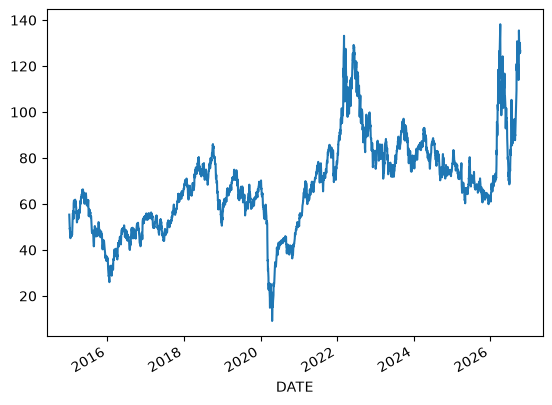

In [2]:
spot = load_brent_spot(start="2015-01-01")
spot.tail()
spot["brent_spot"].plot()

<Axes: xlabel='Date'>

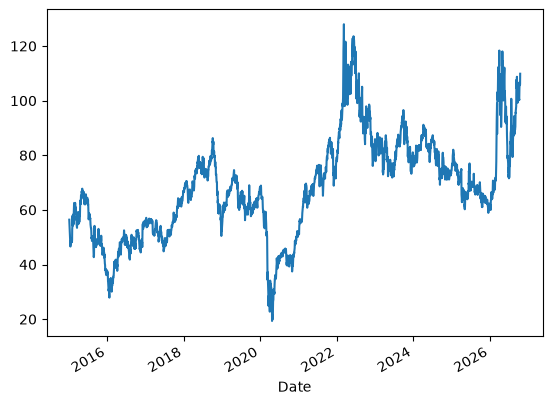

In [2]:
futures = load_brent_futures(start="2015-01-01")
futures.tail()
futures["brent_futures"].plot()

DATE
2015-01-02         NaN
2015-01-05   -0.080825
2015-01-06   -0.018973
2015-01-07   -0.021376
2015-01-08    0.007513
                ...   
2026-10-08    0.032636
2026-10-09   -0.001153
2026-10-12   -0.000615
2026-10-13   -0.032615
2026-10-14    0.006103
Name: brent_spot, Length: 2992, dtype: float64


<Axes: xlabel='DATE'>

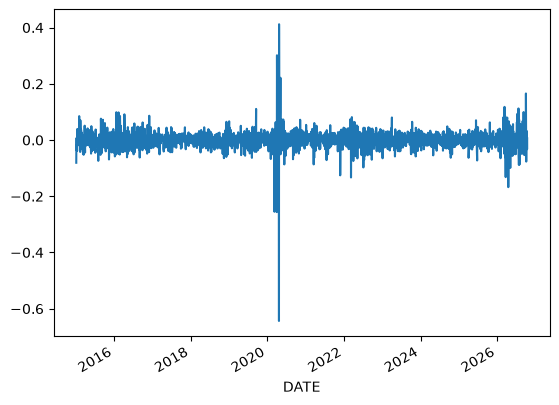

In [5]:
from src.features import log_returns

returns = log_returns(spot)
print(returns)
returns.plot()

In [4]:
spot = load_brent_spot(start="2015-01-01")

results = walk_forward(
    spot["brent_spot"],
    horizon=1,
    start_date="2024-01-01",
    end_date="2026-09-30",
    forecast_funct=random_walk_forecast,
)

results.head()

,origin_date,target_date,forecast,actual
0,2024-01-02,2024-01-03,76.24,77.18
1,2024-01-03,2024-01-04,77.18,75.79
2,2024-01-04,2024-01-05,75.79,78.31
3,2024-01-05,2024-01-08,78.31,75.47
4,2024-01-08,2024-01-09,75.47,77.97


In [6]:
errors = results["actual"] - results['forecast']
mae = errors.abs().mean()
rmse = (errors ** 2).mean() ** 0.5
print(f"MAE: {mae:.3f}, RMSE: {rmse:.3f}")

MAE: 1.604, RMSE: 2.574


In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys
sys.path.append("..")

from src.data import load_brent_spot, load_brent_futures

spot = load_brent_spot(start="2015-01-01")

from src.features import log_returns

data = spot.copy()
data["log_return"] = log_returns(data, col="brent_spot")
data = data.dropna() # remove first row when log return is NA (no previous price to compare to)

from src.models import random_walk_forecast, ar1_forecast
from src.backtest import walk_forward

rw_results = walk_forward(data, horizon=1, start_date="2024-01-01", end_date="2026-09-30", forecast_funct=random_walk_forecast)
ar1_results = walk_forward(data, horizon=1, start_date="2024-01-01", end_date="2026-09-30", forecast_funct=ar1_forecast, lookback = 500)

for name, result in [("Random Walk", rw_results), ("AR(1)", ar1_results)]:
    err = result["actual"] - result["forecast"]
    mae = err.abs().mean()
    rmse = (err ** 2).mean() ** 0.5
    print(f"{name}: MAE={mae:.3f}, RMSE={rmse:.3f}")


Random Walk: MAE=1.604, RMSE=2.574
AR(1): MAE=1.612, RMSE=2.590


In [4]:
lookback_candidates = [100, 250, 500, 1000, 2000]

summary = []
for lb in lookback_candidates:
    res = walk_forward(
        data,
        horizon=1,
        start_date="2024-01-01",
        end_date="2026-09-30",
        forecast_funct=ar1_forecast,
        lookback=lb,
    )
    err = res["actual"] - res["forecast"]
    mae = err.abs().mean()
    rmse = (err ** 2).mean() ** 0.5
    summary.append({"lookback": lb, "MAE": mae, "RMSE": rmse})

summary_df = pd.DataFrame(summary)
summary_df.sort_values("RMSE")

,lookback,MAE,RMSE
4,2000,1.607173,2.574897
3,1000,1.608775,2.584055
2,500,1.612439,2.590181
1,250,1.622623,2.597755
0,100,1.635922,2.623297


In [2]:
spot = load_brent_spot(start="2000-01-01")

data = spot.copy()
data["log_return"] = log_returns(data, col="brent_spot")
data = data.dropna()

rw_results = walk_forward(data, horizon=1, start_date="2024-01-01", end_date="2026-09-30", forecast_funct=random_walk_forecast)
ar1_results = walk_forward(data, horizon=1, start_date="2024-01-01", end_date="2026-09-30", forecast_funct=ar1_forecast, lookback=2000)
mean_results = walk_forward(data, horizon=1, start_date="2024-01-01", end_date="2026-09-30", forecast_funct=historical_mean_forecast, lookback=500)

vol = realised_volatility(data)

results_dict = {
    "Random Walk": rw_results,
    "AR(1), lb=2000": ar1_results,
    "Historical Mean": mean_results,
}

compare_models(results_dict, volatility=vol)


,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,sharpe_ratio,max_drawdown,num_trades
model,,,,,,,,,,,,,,
Random Walk,1.604216,2.574188,1.882614,0.004317,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.0
"AR(1), lb=2000",1.607173,2.574897,1.886152,0.516547,0.520095,0.625000,0.567742,0.511029,0.408824,0.454248,0.109248,0.252164,-0.495710,677.0
Historical Mean,1.605153,2.576447,1.883650,0.502158,0.534884,0.196023,0.286902,0.494700,0.823529,0.618102,0.019534,0.045075,-0.490628,19.0


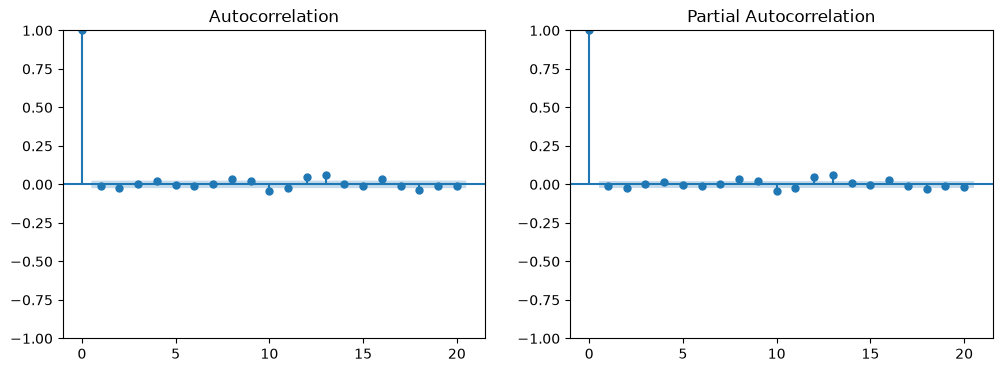

In [ ]:
spot = load_brent_spot(start="2000-01-01")

data = spot.copy()
data["log_return"] = log_returns(data, col="brent_spot")
data = data.dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sm.graphics.tsa.plot_acf(data["log_return"], lags=20, ax=axes[0])
sm.graphics.tsa.plot_pacf(data["log_return"], lags=20, ax=axes[1])
plt.show()

#No significant correlation at any lag.


In [ ]:
spot = load_brent_spot(start="1987-01-01")

data = spot.copy()
data["log_return"] = log_returns(data, col="brent_spot")
data = data.dropna()

lookback_candidates = [500, 1000, 2000, 3000, 5000, 7000]

summary = []
for lb in lookback_candidates:
    res = walk_forward(
        data,
        horizon=1,
        start_date="2024-01-01",
        end_date="2026-09-30",
        forecast_funct=ar1_forecast,
        lookback=lb,
    )
    err = res["actual"] - res["forecast"]
    mae = err.abs().mean()
    rmse = (err ** 2).mean() ** 0.5
    summary.append({"lookback": lb, "MAE": mae, "RMSE": rmse})

summary_df = pd.DataFrame(summary)
summary_df.sort_values("RMSE")

,lookback,MAE,RMSE
5,7000,1.605002,2.574101
4,5000,1.605029,2.574398
3,3000,1.606162,2.574741
2,2000,1.607173,2.574897
1,1000,1.608775,2.584055
0,500,1.612439,2.590181


Notice it converges to random walk (2 cells ago). With more training set, averaged coeff for c and φ (in  c + φ × yesterday's return) both averaged to 0. Therefore forecast is 0 return, which is the same as random walk (tmr price is just todays price).

Check calendar effect next, if any single day can be used as a dummy variable.

                 mean       std  count
day_of_week                           
0           -0.000979  0.027625   1735
1           -0.000804  0.028662   1836
2            0.000413  0.027387   1856
3            0.001378  0.026665   1867
4            0.000967  0.024460   1813
           mean       std  count
month                           
1      0.000812  0.030280    748
2      0.001043  0.022293    706
3      0.000003  0.033208    769
4      0.001852  0.042553    706
5      0.000269  0.023935    751
6      0.000235  0.022312    777
7      0.001098  0.021535    800
8      0.000379  0.022228    801
9      0.000534  0.025171    777
10    -0.001479  0.025146    793
11    -0.000863  0.024194    754
12    -0.001235  0.025181    725


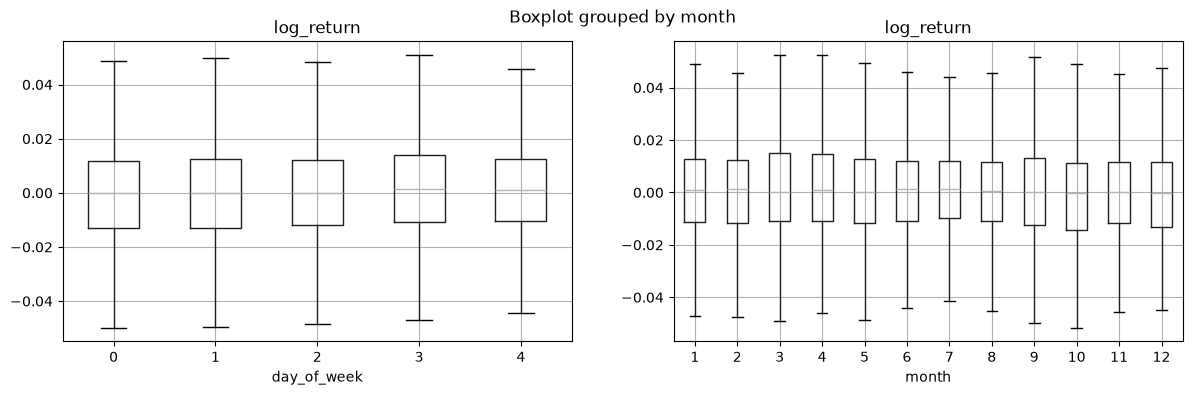

In [8]:
from scipy.stats import kruskal

spot = load_brent_spot(start="1987-01-01")

data = spot.copy()
data["log_return"] = log_returns(data, col="brent_spot")
data = data.dropna()

seasonal = data.copy()
seasonal["day_of_week"] = seasonal.index.dayofweek # (0=Monday, 4=Friday)
seasonal["month"] = seasonal.index.month

print(seasonal.groupby("day_of_week")["log_return"].agg(["mean", "std", "count"])) # do groupby day/month
print(seasonal.groupby("month")["log_return"].agg(["mean", "std", "count"]))

fig, axes = plt.subplots(1,2,figsize = (14, 4))
seasonal.boxplot(column="log_return", by="day_of_week", ax=axes[0], showfliers=False)
seasonal.boxplot(column="log_return", by="month", ax=axes[1], showfliers=False)
plt.show()

In [12]:
groups_days = [g["log_return"].values for _, g in seasonal.groupby("day_of_week")]
groups_months = [g["log_return"].values for _, g in seasonal.groupby("month")]

print("Day of week dist:", kruskal(*groups_days))
print("Months dist:", kruskal(*groups_months))

Day of week dist: KruskalResult(statistic=np.float64(13.57456740858555), pvalue=np.float64(0.00878427932615768))
Months dist: KruskalResult(statistic=np.float64(14.83740304946368), pvalue=np.float64(0.19006237574170223))


P-value for day of week seem significant since p-val < 0.05. 

In [16]:
# For whole training set
pre_val_period = seasonal[seasonal.index < "2024-01-01"]

groups = [g["log_return"].values for _, g in pre_val_period.groupby("day_of_week")]
print(kruskal(*groups))
print(pre_val_period.groupby("day_of_week")["log_return"].agg(["mean", "std", "count"]))


# Recent years of training set
recent_pre_val_period = seasonal[(seasonal.index >= "2015-01-01") & (seasonal.index < "2024-01-01")]

groups = [g["log_return"].values for _, g in recent_pre_val_period.groupby("day_of_week")]
print(kruskal(*groups))
print(recent_pre_val_period.groupby("day_of_week")["log_return"].agg(["mean", "std", "count"]))




KruskalResult(statistic=np.float64(12.474617678986375), pvalue=np.float64(0.014149734625531584))
                 mean       std  count
day_of_week                           
0           -0.000874  0.027493   1602
1           -0.001003  0.028743   1690
2            0.000548  0.027502   1712
3            0.001160  0.026630   1725
4            0.000948  0.023948   1672
KruskalResult(statistic=np.float64(2.7440294326678334), pvalue=np.float64(0.601532308959124))
                 mean       std  count
day_of_week                           
0           -0.001989  0.030997    434
1           -0.001709  0.040914    462
2            0.001760  0.033333    466
3            0.000819  0.028922    468
4            0.001732  0.026302    456


While the days have different return means, compared to the noise 2%, its a tiny difference. (e.g. Thursday (+0.12%)vs Monday (-ve 0.1%) is < 0.22%, but std devatiation (noise) is ~ 2.7%)

Converted to price: forecast = today's price × exp(predicted return). On a $100 barrel:

Thursday: 100 × exp(0.00116) ≈ $100.12
Tuesday: 100 × exp(−0.001003) ≈ $99.90
Random walk: $100.00
So the dummy moves the forecast by about 10–12 cents.

Our RW MAE is around $1.60. So a dummy variable shifting by 10cents wont greatly reduce our MAE. There no reason to add calendar effect also.

Additionally, if you isolate for recent years only, the p-value > 0.05, and no weekday is significant.

